# 05 - Projections: tiers, probabilities and comparables

A single predicted VORP is an *average* of many possible futures, so it is
always cautious. This notebook turns predictions into something richer:

1. **Tiers**: what the target means in basketball terms
2. **Tier probabilities**: "players projected like him became All-Stars X% of the time"
3. **Are those probabilities trustworthy?** (scored against what really happened)
4. **Style comparables**: who he looked like in his first 25 games
5. **Player cards**: everything together

All on the development set (classes 2000-2013) with out-of-fold predictions.
The logic lives in `src/projection.py`, so the current rookies get exactly the
same treatment later.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
import projection as pj
from plot_style import apply_style, BLUE, ORANGE, NEUTRAL, INK_2, SEQ_BLUE

apply_style()
dev = m.dev_set(md.add_pick_terms(m.load_table()))

# Out-of-fold predictions (5 repeats x 5 folds)
_, model_oof = m.repeated_cv(md.ensemble, md.ALL, dev)
_, base_oof = m.repeated_cv(md.baseline, ["pick"], dev)
quant = {}
for q in [0.1, 0.5, 0.9]:
    _, quant[q] = m.repeated_cv(lambda q=q: md.boosting(loss="quantile", quantile=q), md.ALL, dev)
qs = np.sort(np.column_stack([quant[0.1], quant[0.5], quant[0.9]]), axis=1)  # no crossing
dev = dev.assign(model_pred=model_oof, base_pred=base_oof,
                 p10=qs[:, 0], p50=qs[:, 1], p90=qs[:, 2],
                 tier=pj.tier_of(dev[m.TARGET]))
print(f"Development set: {len(dev)} players")

# Ordinal colours for the tiers: one blue ramp, light (low tier) to dark (high)
TIER_COLORS = [to_hex(SEQ_BLUE(x)) for x in np.linspace(0.18, 0.95, len(pj.TIER_NAMES))]

Development set: 683 players


## 1. The tiers

Cut-offs on VORP summed over years 3 and 4 (roughly: per season, ~1-2 is a
rotation player, ~2-3 a starter, 3+ an All-Star-level season).

In [2]:
counts = dev["tier"].value_counts().reindex(pj.TIER_NAMES)
examples = (dev.sort_values(m.TARGET, ascending=False).groupby("tier", observed=True)["player_name"]
            .apply(lambda s: ", ".join(s.head(5))))
tier_table = pd.DataFrame({
    "VORP 3+4": [f"{lo:g} to {hi:g}".replace("-inf to ", "below ").replace(" to inf", " or more")
                 for _, lo, hi in pj.TIERS],
    "players": counts.values,
    "share": (counts / counts.sum()).round(3).values,
    "examples (highest VORP first)": examples.reindex(pj.TIER_NAMES).values,
}, index=pj.TIER_NAMES)
tier_table

,VORP 3+4,players,share,examples (highest VORP first)
Little or no value,below 0.5,407,0.596,"Chris Wilcox, Iman Shumpert, Eddie House, Shel..."
Bench,0.5 to 2,126,0.184,"Cory Joseph, Josh McRoberts, Patrick Patterson..."
Rotation,2 to 4,79,0.116,"Leandro Barbosa, Ronnie Brewer, David West, Ja..."
Starter,4 to 6,36,0.053,"Marc Gasol, Kevin Martin, Pau Gasol, Isaiah Th..."
All-Star level,6 or more,35,0.051,"Chris Paul, LeBron James, Kevin Durant, Dwyane..."


**What to look for:** the shape of the pyramid (most rookies end up with little
value, only a few percent reach All-Star level) and whether the example names
make basketball sense. Remember the target mixes quality and volume over two
specific seasons: Kawhi Leonard (7.6) only just clears the All-Star cut, Steph
Curry (6.8) had injuries in those years.

## 2. Tier probabilities: neighbours in predicted value

For each player, look at the other players whose out-of-fold prediction was
close to his, and count which tier they really reached. (Leave-one-out: a
player is never his own neighbour.) Two ways to define "close":

- **k nearest**: the k closest predictions, each counting the same
- **Kernel**: everyone counts, with a weight that falls with the distance in
  prediction (a bell curve whose width is the *bandwidth*, in VORP units)

- **Adaptive kernel**: the kernel, plus the N closest players always counting in
  full

Why three versions? k-NN has a flaw at the top: every top prospect shares the same
top-k group, so LeBron, Derrick Rose and Damian Lillard get identical percentages
despite different predictions. A plain kernel fixes that but has the opposite
problem: so few players were ever predicted that high that a top prospect's
percentages rest on 2 or 3 players. The adaptive kernel keeps the kernel's
resolution in the crowded middle and guarantees a minimum sample at the top.

Settings are chosen by the **Brier score**: the squared distance between the
predicted probabilities and what really happened (lower is better).

In [3]:
truth = dev[m.TARGET]
def score(pred_col, **kw):
    return pj.brier_score(pj.tier_probabilities(dev[pred_col], dev[pred_col], truth,
                                                exclude_self=True, **kw), truth)

ks = [25, 50, 100, 150]
bandwidths = [0.25, 0.5, 0.75, 1.0]
rows = []
for k in ks:
    rows.append({"method": "k nearest", "setting": f"k={k}",
                 "Model (pick + 25 games)": score("model_pred", k=k), "Pick only": score("base_pred", k=k)})
for h in bandwidths:
    rows.append({"method": "kernel", "setting": f"bandwidth={h}",
                 "Model (pick + 25 games)": score("model_pred", bandwidth=h), "Pick only": score("base_pred", bandwidth=h)})
MIN_NS = [15, 25, 50]
for n in MIN_NS:
    rows.append({"method": "adaptive kernel", "setting": f"0.5, at least {n}",
                 "Model (pick + 25 games)": score("model_pred", bandwidth=0.5, min_neighbors=n),
                 "Pick only": score("base_pred", bandwidth=0.5, min_neighbors=n)})
brier = pd.DataFrame(rows).set_index(["method", "setting"])

# No information at all: everyone gets the overall tier shares
base_rates = dev["tier"].value_counts(normalize=True).reindex(pj.TIER_NAMES)
no_info = pj.brier_score(pd.DataFrame([base_rates.values] * len(dev), columns=pj.TIER_NAMES), truth)
print(f"Brier - no information: {no_info:.3f}")
brier.round(4)

Brier - no information: 0.592


Model (pick + 25 games)  Pick only
method          setting                                             
k nearest       k=25                               0.5522     0.5817
                k=50                               0.5378     0.5689
                k=100                              0.5344     0.5659
                k=150                              0.5350     0.5663
kernel          bandwidth=0.25                     0.5383     0.5706
                bandwidth=0.5                      0.5355     0.5702
                bandwidth=0.75                     0.5387     0.5724
                bandwidth=1.0                      0.5437     0.5751
adaptive kernel 0.5, at least 15                   0.5346     0.5699
                0.5, at least 25                   0.5331     0.5699
                0.5, at least 50                   0.5322     0.5703

Best k nearest        Brier: 0.5344 (k=100)
Best kernel           Brier: 0.5355 (bandwidth=0.5)
Best adaptive kernel  Brier: 0.5322 (0.5, at least 50)
Chosen: adaptive kernel, bandwidth 0.5, at least 50 players


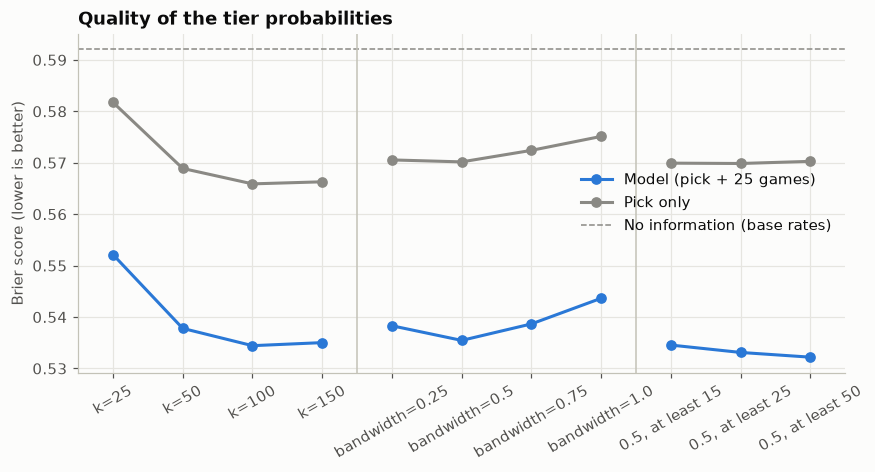

In [4]:
BANDWIDTH = 0.5
model_col = brier["Model (pick + 25 games)"]
adaptive = model_col.loc["adaptive kernel"]
MIN_NEIGHBORS = int(adaptive.idxmin().split("at least ")[1])
for method in ["k nearest", "kernel", "adaptive kernel"]:
    print(f"Best {method:16s} Brier: {model_col.loc[method].min():.4f} ({model_col.loc[method].idxmin()})")
print(f"Chosen: adaptive kernel, bandwidth {BANDWIDTH}, at least {MIN_NEIGHBORS} players")

fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{a}\n{b}" for a, b in brier.index]
x = np.arange(len(brier))
# one line per method, so the two methods aren't joined as if they were a sequence
for j, method in enumerate(["k nearest", "kernel", "adaptive kernel"]):
    sel = np.array([i for i, (meth, _) in enumerate(brier.index) if meth == method])
    ax.plot(sel, brier["Model (pick + 25 games)"].iloc[sel], color=BLUE, marker="o", markersize=6,
            label="Model (pick + 25 games)" if j == 0 else None)
    ax.plot(sel, brier["Pick only"].iloc[sel], color=NEUTRAL, marker="o", markersize=6,
            label="Pick only" if j == 0 else None)
ax.axhline(no_info, color=NEUTRAL, linestyle="--", linewidth=1, label="No information (base rates)")
for cut in [len(ks) - 0.5, len(ks) + len(bandwidths) - 0.5]:
    ax.axvline(cut, color="#c3c2b7", linewidth=1)
ax.set_xticks(x, [b for _, b in brier.index], rotation=30)
ax.set(title="Quality of the tier probabilities", ylabel="Brier score (lower is better)")
ax.legend(loc="center right")
plt.show()

**What to look for:** the gap between the blue and grey lines is how much the
first 25 games improve the *probabilities*, not just the point prediction. If the
adaptive kernel scores about as well as the best k-NN overall, it wins: it keeps
the top prospects distinguishable without resting on a handful of players.

In [5]:
probs = pj.tier_probabilities(dev["model_pred"], dev["model_pred"], truth,
                              bandwidth=BANDWIDTH, min_neighbors=MIN_NEIGHBORS, exclude_self=True)
probs_pick = pj.tier_probabilities(dev["base_pred"], dev["base_pred"], truth,
                                   bandwidth=BANDWIDTH, min_neighbors=MIN_NEIGHBORS, exclude_self=True)
dev["p_starter_plus"] = probs[["Starter", "All-Star level"]].sum(axis=1)
dev["p_allstar"] = probs["All-Star level"]
dev["p_starter_plus_pick"] = probs_pick[["Starter", "All-Star level"]].sum(axis=1)
dev["p_bust"] = probs["Little or no value"]
print(f"Effective players behind each player's percentages: median {probs['n_eff'].median():.0f}, "
      f"smallest {probs['n_eff'].min():.0f}")
print(f"Highest P(All-Star level): {dev['p_allstar'].max():.0%} | "
      f"highest P(starter or better): {dev['p_starter_plus'].max():.0%}")

Effective players behind each player's percentages: median 401, smallest 50
Highest P(All-Star level): 38% | highest P(starter or better): 56%


## 3. Can the probabilities be trusted?

**Reliability:** group players by their predicted chance of becoming at least a
starter, and check how many really did. If the model says 30%, about 30% of those
players should have made it. Points on the diagonal = trustworthy percentages.

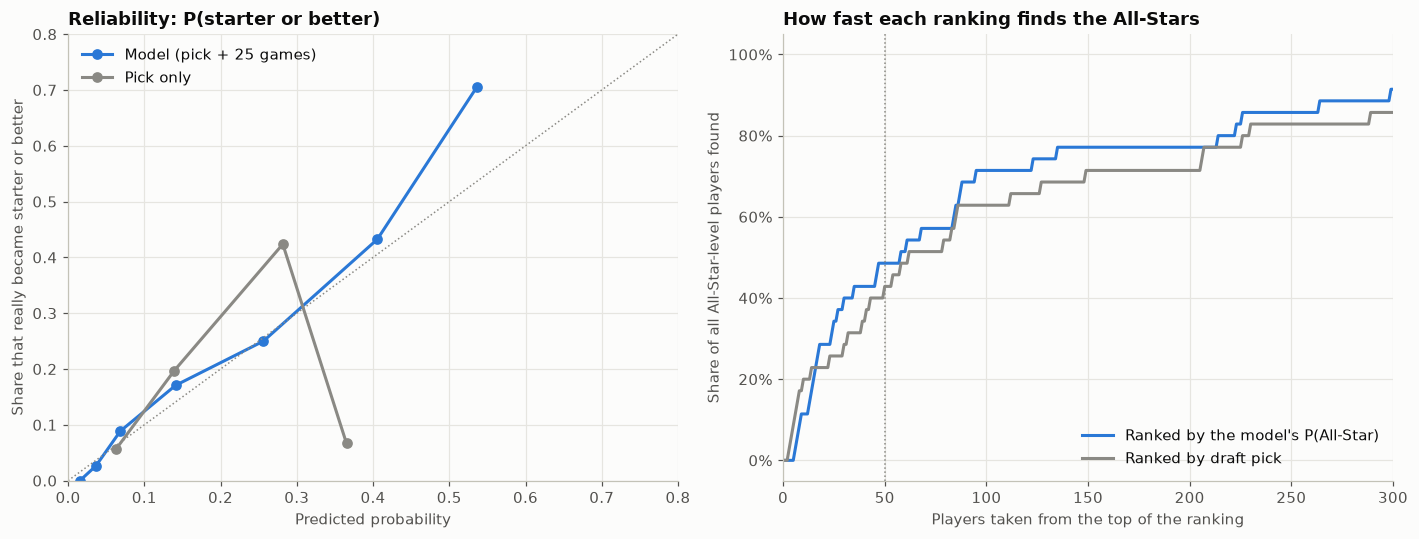

All-Star-level players in the development set: 35
Found in the top 50 - by model: 17, by pick: 15


In [6]:
became = dev["tier"].isin(["Starter", "All-Star level"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
for col, label, color in [("p_starter_plus", "Model (pick + 25 games)", BLUE),
                          ("p_starter_plus_pick", "Pick only", NEUTRAL)]:
    bins = pd.cut(dev[col], [-0.01, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0])
    g = pd.DataFrame({"pred": dev[col], "real": became}).groupby(bins, observed=True).agg(
        pred=("pred", "mean"), real=("real", "mean"), n=("real", "size"))
    g = g[g["n"] >= 15]  # tiny groups give meaningless shares
    ax.plot(g["pred"], g["real"], color=color, marker="o", markersize=6, label=label)
ax.plot([0, 0.8], [0, 0.8], color=NEUTRAL, linestyle=":", linewidth=1)
ax.set(title="Reliability: P(starter or better)", xlabel="Predicted probability",
       ylabel="Share that really became starter or better", xlim=(0, 0.8), ylim=(0, 0.8))
ax.legend(loc="upper left")

ax = axes[1]
top = dev.sort_values("p_allstar", ascending=False)
share = top["tier"].eq("All-Star level").cumsum() / top["tier"].eq("All-Star level").sum()
ax.plot(np.arange(1, len(top) + 1), share.values, color=BLUE, label="Ranked by the model's P(All-Star)")
pick_rank = dev.sort_values("pick")
share_pick = pick_rank["tier"].eq("All-Star level").cumsum() / pick_rank["tier"].eq("All-Star level").sum()
ax.plot(np.arange(1, len(top) + 1), share_pick.values, color=NEUTRAL, label="Ranked by draft pick")
ax.axvline(50, color=NEUTRAL, linestyle=":", linewidth=1)
ax.set(title="How fast each ranking finds the All-Stars", xlabel="Players taken from the top of the ranking",
       ylabel="Share of all All-Star-level players found", xlim=(0, 300))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

n_as = dev["tier"].eq("All-Star level").sum()
print(f"All-Star-level players in the development set: {n_as}")
print(f"Found in the top 50 - by model: {int(top.head(50)['tier'].eq('All-Star level').sum())}, "
      f"by pick: {int(pick_rank.head(50)['tier'].eq('All-Star level').sum())}")

**Left:** how close each line stays to the diagonal. The pick-only line's last
point (about 37% predicted, 7% real) is a cross-validation artefact worth knowing:
there are few #1 and #2 picks per fold, so when a #1-pick bust's class is held out
the training folds keep the #1-pick stars (e.g. LeBron) and the pick curve goes
*up*; when LeBron's class is held out it goes *down*. Busts end up with the highest
pick-only probabilities by construction. The model is less exposed because it can
tell picks apart by their first 25 games. **Right:** imagine scouting
the players ranked highest first. The steeper the curve, the faster that ranking
finds the future All-Stars. The dotted line marks the top 50 (about 3.5 drafts'
worth of lottery picks).

## 4. Style comparables: who did he look like?

k-NN on the window profile: position, age, minutes, usage, scoring, playmaking,
rebounding, rim protection, steals, 3-point and free-throw rates, efficiency.
Every feature is standardised so each counts the same. This answers "who did he
*look like*", which is a different question from "what will he become".

In [7]:
SHOW = ["Draymond Green", "Damian Lillard", "Marc Gasol", "Kawhi Leonard",
        "Stephen Curry", "Dwight Howard", "Anthony Bennett", "Michael Carter-Williams"]
comps = pj.style_comps(dev[dev["player_name"].isin(SHOW)], dev, k=5)
(comps.assign(comp=lambda d: d["comp"] + " (#" + d["comp_pick"].astype(str) + ", "
              + d["comp_draft_year"].astype(str) + ")")
      .pivot(index="player", columns="rank", values="comp")
      .reindex([s for s in SHOW if s in set(comps["player"])]))

rank,1,2,3,4,5
player,,,,,
Draymond Green,"Chandler Parsons (#38, 2011)","Anthony Bennett (#1, 2013)","Terence Morris (#33, 2001)","Corey Brewer (#7, 2007)","Victor Claver (#22, 2009)"
Damian Lillard,"D.J. Augustin (#9, 2008)","Jonny Flynn (#6, 2009)","Brandon Jennings (#10, 2009)","Trey Burke (#9, 2013)","LeBron James (#1, 2003)"
Marc Gasol,"Semih Erden (#60, 2008)","Paul Millsap (#47, 2006)","Leon Powe (#49, 2006)","Alexander Johnson (#45, 2006)","Jamaal Magloire (#19, 2000)"
Kawhi Leonard,"Josh Childress (#6, 2004)","Chris Porter (#55, 2000)","Marvin Williams (#2, 2005)","Thabo Sefolosha (#13, 2006)","Al-Farouq Aminu (#8, 2010)"
Stephen Curry,"Iman Shumpert (#17, 2011)","Khalid El-Amin (#34, 2000)","Mario Chalmers (#34, 2008)","Devin Harris (#5, 2004)","Jay Williams (#2, 2002)"
Dwight Howard,"Greg Oden (#1, 2007)","Amar'e Stoudemire (#9, 2002)","Derrick Favors (#3, 2010)","Brendan Haywood (#20, 2001)","Steven Adams (#12, 2013)"
Anthony Bennett,"Nikoloz Tskitishvili (#5, 2002)","Otto Porter Jr. (#3, 2013)","Shannon Brown (#25, 2006)","Will Barton (#40, 2012)","Luke Babbitt (#16, 2010)"
Michael Carter-Williams,"John Wall (#1, 2010)","Chris Paul (#4, 2005)","Russell Westbrook (#4, 2008)","Victor Oladipo (#2, 2013)","Luke Ridnour (#14, 2003)"


**What to look for:** do the comps make basketball sense? Bigs should match bigs,
playmaking guards should match playmaking guards. They describe the *profile*
in the first 25 games, so a comp can have a very different career.

## 5. Player cards

Everything together, out-of-fold: the model never saw the player it describes.

In [8]:
def card(name):
    r = dev[dev["player_name"] == name].iloc[0]
    p = probs.loc[r.name]
    c = pj.style_comps(dev.loc[[r.name]], dev, k=3)
    lines = [
        f"{name} - #{int(r['pick'])} pick, {int(r['draft_year'])}, debut at {int(r['age_at_debut'])}",
        f"  First 25 games: {r['mpg']:.1f} mpg, {r['games_played']:.0f} games played",
        f"  Pick alone expected: {r['base_pred']:.1f} VORP | model central case: {r['model_pred']:.1f}",
        f"  Floor (p10) {r['p10']:.1f} | median (p50) {r['p50']:.1f} | ceiling (p90) {r['p90']:.1f}",
        "  Tier probabilities: " + " | ".join(f"{t} {p[t]:.0%}" for t in pj.TIER_NAMES)
        + f"  (based on ~{p['n_eff']:.0f} similar players)",
        "  Looked like: " + ", ".join(f"{x} (#{y}, {z})" for x, y, z in
                                       zip(c["comp"], c["comp_pick"], c["comp_draft_year"])),
        f"  What happened: {r[m.TARGET]:.1f} VORP -> {r['tier']}",
    ]
    print("\n".join(lines) + "\n")

for name in ["Damian Lillard", "Draymond Green", "Marc Gasol", "Anthony Bennett",
             "Michael Carter-Williams"]:
    card(name)

Damian Lillard - #6 pick, 2012, debut at 22
  First 25 games: 37.9 mpg, 25 games played
  Pick alone expected: 2.3 VORP | model central case: 5.4
  Floor (p10) -0.2 | median (p50) 2.8 | ceiling (p90) 8.0
  Tier probabilities: Little or no value 16% | Bench 8% | Rotation 24% | Starter 18% | All-Star level 34%  (based on ~50 similar players)
  Looked like: D.J. Augustin (#9, 2008), Jonny Flynn (#6, 2009), Brandon Jennings (#10, 2009)
  What happened: 9.2 VORP -> All-Star level

Draymond Green - #35 pick, 2012, debut at 22
  First 25 games: 14.7 mpg, 25 games played
  Pick alone expected: 0.6 VORP | model central case: 1.4
  Floor (p10) -0.2 | median (p50) 0.9 | ceiling (p90) 3.2
  Tier probabilities: Little or no value 53% | Bench 26% | Rotation 13% | Starter 5% | All-Star level 3%  (based on ~332 similar players)
  Looked like: Chandler Parsons (#38, 2011), Anthony Bennett (#1, 2013), Terence Morris (#33, 2001)
  What happened: 8.8 VORP -> All-Star level

Marc Gasol - #48 pick, 2007, de

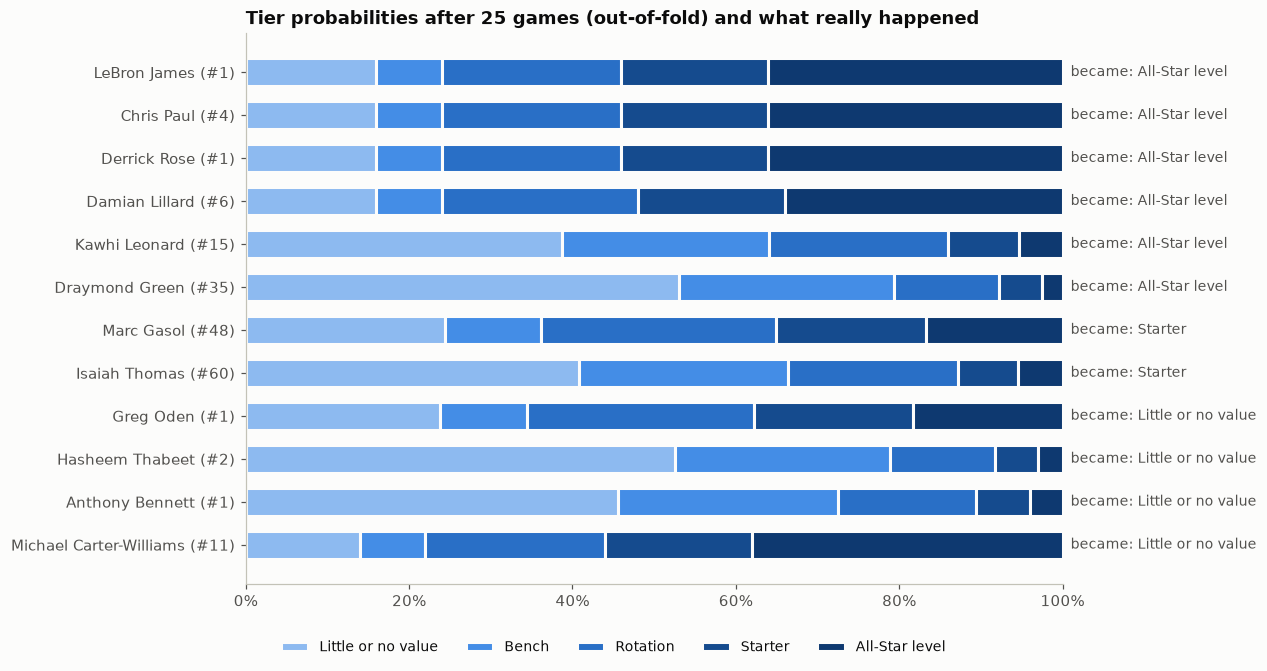

In [9]:
SHOWCASE = ["LeBron James", "Chris Paul", "Derrick Rose", "Damian Lillard", "Kawhi Leonard",
            "Draymond Green", "Marc Gasol", "Isaiah Thomas", "Greg Oden", "Hasheem Thabeet",
            "Anthony Bennett", "Michael Carter-Williams"]
rows = [dev.index[dev["player_name"] == n][0] for n in SHOWCASE if (dev["player_name"] == n).any()]
sel = dev.loc[rows].set_index("player_name")
P = probs.loc[rows]

fig, ax = plt.subplots(figsize=(11, 6.5))
left = np.zeros(len(sel))
for t, color in zip(pj.TIER_NAMES, TIER_COLORS):
    vals = P[t].to_numpy()
    ax.barh(range(len(sel)), vals, left=left, color=color, height=0.65,
            edgecolor="#fcfcfb", linewidth=2, label=t)
    left += vals
for i, (name, r) in enumerate(sel.iterrows()):
    ax.annotate(f"became: {r['tier']}", (1.01, i), va="center", fontsize=9, color=INK_2,
                annotation_clip=False)
ax.set_yticks(range(len(sel)), [f"{n} (#{int(r['pick'])})" for n, r in sel.iterrows()])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.08), fontsize=9)
ax.set_title("Tier probabilities after 25 games (out-of-fold) and what really happened")
plt.subplots_adjust(right=0.8)
plt.show()

**What to look for:** the darker the bar's right end, the more upside the model
saw. Busts should show mostly light segments; stars should show real dark
segments even when their *average* prediction was modest. That is exactly the
"not too conservative" view: a 25% All-Star chance is a bold, honest statement.